Descrição do projeto
Você se saiu muito bem no curso da TripleTen e recebeu uma oferta de estágio no departamento analítico da Y.Afisha. Sua primeira tarefa é ajudar a empresa a otimizar suas despesas com marketing.

Você tem:

Logs do servidor com dados sobre os acessos a Y.Afisha de janeiro de 2017 até dezembro de 2018
Arquivo de despejo (ou dump file, em inglês) com todos os pedidos feitos durante o período
Estatísticas de despesas com marketing
Você vai analisar:

Como as pessoas usam o produto
Quando elas começam a comprar
Quanto dinheiro cada cliente traz para a empresa
Quando as despesas serão cobertas

In [13]:
#importando as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [14]:

#lendo os arquivos - visits
df_visits = pd.read_csv('visits_log_us.csv',dtype={'Device': 'category'},
    parse_dates=['Start Ts', 'End Ts'],
)
#alterando o cabeçalho para minúsculoas e colocando o underscore
df_visits.columns = df_visits.columns.str.lower().str.replace(' ','_')
#adicionando as colunas de datas(dia,semana, mês e ano)
df_visits['dt_day'] = df_visits['start_ts'].dt.day
df_visits['dt_week'] = df_visits['start_ts'].dt.isocalendar().week
df_visits['dt_month'] = df_visits['start_ts'].dt.month
df_visits['dt_year'] = df_visits['start_ts'].dt.year
df_visits['dt_date'] = df_visits['start_ts'].dt.date
#calculando a duração das sessões
df_visits['session_duration'] = (df_visits['end_ts'] - df_visits['start_ts']).dt.total_seconds() / 60
df_visits['session_duration'] = df_visits['session_duration'].round().astype('int')
print(df_visits.head(10))
df_visits.info()


    device              end_ts  source_id            start_ts  \
0    touch 2017-12-20 17:38:00          4 2017-12-20 17:20:00   
1  desktop 2018-02-19 17:21:00          2 2018-02-19 16:53:00   
2    touch 2017-07-01 01:54:00          5 2017-07-01 01:54:00   
3  desktop 2018-05-20 11:23:00          9 2018-05-20 10:59:00   
4  desktop 2017-12-27 14:06:00          3 2017-12-27 14:06:00   
5  desktop 2017-09-03 21:36:00          5 2017-09-03 21:35:00   
6  desktop 2018-01-30 12:09:00          1 2018-01-30 11:13:00   
7    touch 2017-11-05 15:15:00          3 2017-11-05 15:14:00   
8  desktop 2017-07-19 10:44:00          3 2017-07-19 10:41:00   
9  desktop 2017-11-08 13:43:00          5 2017-11-08 13:42:00   

                    uid  dt_day  dt_week  dt_month  dt_year     dt_date  \
0  16879256277535980062      20       51        12     2017  2017-12-20   
1    104060357244891740      19        8         2     2018  2018-02-19   
2   7459035603376831527       1       26         7     2017

In [15]:
#lendo os arquivos - orders
df_orders = pd.read_csv('orders_log_us.csv',parse_dates=['Buy Ts'])
#alterando o cabeçalho para minúsculoas e colocando o underscore
df_orders.columns = df_orders.columns.str.lower().str.replace(' ','_')
#adicionando as colunas de datas(dia,semana, mês e ano)
df_orders['dt_day'] = df_orders['buy_ts'].dt.day
df_orders['dt_week'] = df_orders['buy_ts'].dt.isocalendar().week
df_orders['dt_month'] = df_orders['buy_ts'].dt.month
df_orders['dt_year'] = df_orders['buy_ts'].dt.year
df_orders['dt_date'] = df_orders['buy_ts'].dt.date
print(df_orders.head(10))
df_orders.info()

               buy_ts  revenue                   uid  dt_day  dt_week  \
0 2017-06-01 00:10:00    17.00  10329302124590727494       1       22   
1 2017-06-01 00:25:00     0.55  11627257723692907447       1       22   
2 2017-06-01 00:27:00     0.37  17903680561304213844       1       22   
3 2017-06-01 00:29:00     0.55  16109239769442553005       1       22   
4 2017-06-01 07:58:00     0.37  14200605875248379450       1       22   
5 2017-06-01 08:43:00     0.18  10402394430196413321       1       22   
6 2017-06-01 08:54:00     1.83  12464626743129688638       1       22   
7 2017-06-01 09:22:00     1.22   3644482766749211722       1       22   
8 2017-06-01 09:22:00     3.30  17542070709969841479       1       22   
9 2017-06-01 09:23:00     0.37   1074355127080856382       1       22   

   dt_month  dt_year     dt_date  
0         6     2017  2017-06-01  
1         6     2017  2017-06-01  
2         6     2017  2017-06-01  
3         6     2017  2017-06-01  
4         6     2017 

In [16]:

#lendo os arquivos - costs
df_costs = pd.read_csv('costs_us.csv',dtype={'source_id': 'category'},
    parse_dates=['dt'],
)
#adicionando as colunas de datas(dia,semana, mês e ano)
df_costs['dt_day'] = df_costs['dt'].dt.day
df_costs['dt_week'] = df_costs['dt'].dt.isocalendar().week
df_costs['dt_month'] = df_costs['dt'].dt.month
df_costs['dt_year'] = df_costs['dt'].dt.year
df_costs['dt_date'] = df_costs['dt'].dt.date
#transformando a coluna source_id em número inteiro
df_costs['source_id'] = df_costs['source_id'].astype(int)
print(df_costs.head(10))
df_costs.info()

   source_id         dt  costs  dt_day  dt_week  dt_month  dt_year     dt_date
0          1 2017-06-01  75.20       1       22         6     2017  2017-06-01
1          1 2017-06-02  62.25       2       22         6     2017  2017-06-02
2          1 2017-06-03  36.53       3       22         6     2017  2017-06-03
3          1 2017-06-04  55.00       4       22         6     2017  2017-06-04
4          1 2017-06-05  57.08       5       23         6     2017  2017-06-05
5          1 2017-06-06  40.39       6       23         6     2017  2017-06-06
6          1 2017-06-07  40.59       7       23         6     2017  2017-06-07
7          1 2017-06-08  56.63       8       23         6     2017  2017-06-08
8          1 2017-06-09  40.16       9       23         6     2017  2017-06-09
9          1 2017-06-10  43.24      10       23         6     2017  2017-06-10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 8 columns):
 #   Column     Non-Null 

In [17]:
#Produto - Quantas pessoas usam-no cada dia, semana e mês?
#o número de usuários ativos únicos por dia
dau_total = df_visits.groupby('dt_date').agg({'uid':'nunique'}).mean()
#o número de usuários ativos únicos por semana
wau_total = df_visits.groupby(['dt_year', 'dt_week']).agg({'uid':'nunique'}).mean()
#o número de usuários ativos únicos por mês
mau_total = df_visits.groupby(['dt_year', 'dt_month']).agg({'uid':'nunique'}).mean()

print("O número de usuários ativos únicos por dia:", int(dau_total))
print("O número de usuários ativos únicos por semana:", int(wau_total))
print("O número de usuários ativos únicos por mês:", int(mau_total))


O número de usuários ativos únicos por dia: 907
O número de usuários ativos únicos por semana: 5716
O número de usuários ativos únicos por mês: 23228


C:\Users\dezac\AppData\Local\Temp\ipykernel_368\882214609.py:9: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  print("O número de usuários ativos únicos por dia:", int(dau_total))
C:\Users\dezac\AppData\Local\Temp\ipykernel_368\882214609.py:10: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  print("O número de usuários ativos únicos por semana:", int(wau_total))
C:\Users\dezac\AppData\Local\Temp\ipykernel_368\882214609.py:11: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  print("O número de usuários ativos únicos por mês:", int(mau_total))


In [18]:
 #Quantas sessões ocorrem por dia? (um usuário pode realizar várias sessões).
qtd_session_day = df_visits.groupby('dt_date').agg({'uid':['count','nunique']})
qtd_session_day.columns = ['sessions', 'users']
qtd_session_day['sessions_per_user'] = qtd_session_day['sessions'] / qtd_session_day['users']

print(f"Média de sessões por usuário por dia: {qtd_session_day['sessions_per_user'].mean():.2f}")


Média de sessões por usuário por dia: 1.08


In [19]:
#Que comprimento tem cada sessão?
df_visits['session_duration'] = (df_visits['end_ts'] - df_visits['start_ts']).dt.total_seconds() / 60
print("Cada sessão tem em média:", df_visits['session_duration'].mean(), "minutos")

Cada sessão tem em média: 10.717094787608978 minutos


In [20]:
df_visits['session_duration'].describe()

count    359400.000000
mean         10.717095
std          16.618796
min         -46.000000
25%           2.000000
50%           5.000000
75%          14.000000
max         711.000000
Name: session_duration, dtype: float64

A média está acima da mediana, indica que pode ter sessões muito longas puxando o valor.
A mediana está em 5 minutos.
Isso pode indicar que o produto é usado de forma rápida e pontual.

0     1.000000
1     0.078664
2     0.053775
3     0.061392
4     0.068557
        ...   
73    0.041818
74    0.027053
75    1.000000
76    0.048380
77    1.000000
Name: retention_rate, Length: 78, dtype: float64


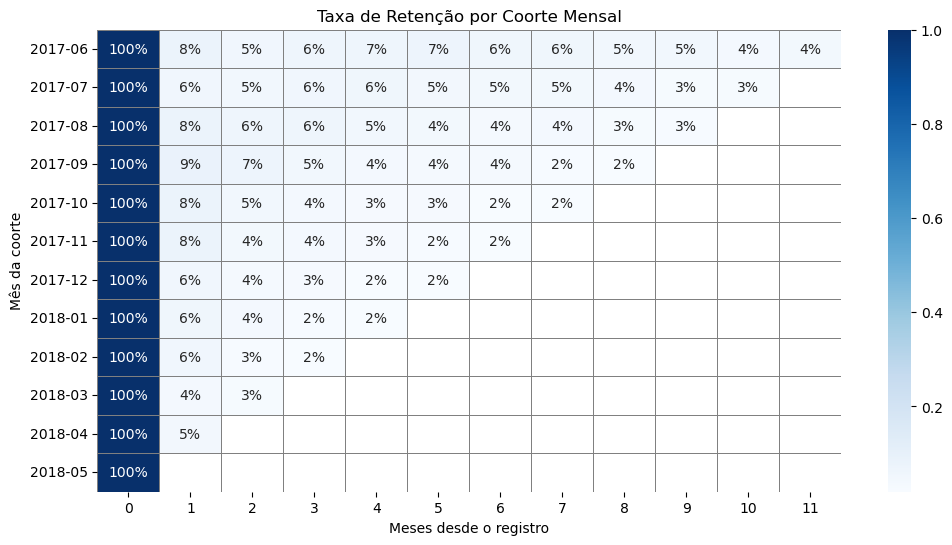

In [21]:
#Com que frequência os usuários voltam? - taxa de retenção
#encontrar a primeira visita de cada usuário
# Extrair dia de registro (primeira visita)
# Criar coluna de mês de registro
df_visits['cohort_month'] = df_visits.groupby('uid')['start_ts'].transform('min').dt.to_period('M')

# Criar coluna de mês da visita
df_visits['visit_month'] = df_visits['start_ts'].dt.to_period('M')

# Diferença entre mês da visita e mês de registro
df_visits['months_since_signup'] = (df_visits['visit_month'] - df_visits['cohort_month']).apply(lambda x: x.n)

#Calcular retenção
# Usuários únicos por coorte e mês relativo
monthly_retention = (
    df_visits.groupby(['cohort_month','months_since_signup'])['uid']
    .nunique()
    .reset_index()
)

# Tamanho da coorte inicial
cohort_sizes = (
    df_visits[df_visits['months_since_signup'] == 0]
    .groupby('cohort_month')['uid']
    .nunique()
    .reset_index(name='cohort_size')
)

# Juntar e calcular taxa de retenção
monthly_retention = monthly_retention.merge(cohort_sizes, on='cohort_month')
monthly_retention['retention_rate'] = monthly_retention['uid'] / monthly_retention['cohort_size']
print(monthly_retention['retention_rate'])
# Pivot para heatmap
retention_matrix = monthly_retention.pivot(index='cohort_month', columns='months_since_signup', values='retention_rate')


plt.figure(figsize=(12, 6))
sns.heatmap(retention_matrix, cmap="Blues", annot=True, fmt=".0%", linewidths=0.5, linecolor='gray')
plt.title('Taxa de Retenção por Coorte Mensal')
plt.xlabel('Meses desde o registro')
plt.ylabel('Mês da coorte')
plt.show()


O produto/serviço não está retendo bem os usuários ao longo dos meses.
A retenção média após o primeiro mês é inferior a 10%, o que indica que a maioria dos usuários não encontra valor contínuo, faz-se necessário investir em engajamento recorrente e valor de longo prazo para aumentar a retenção, campanhas pontuais podem ajudar, mas não sustentam o engajamento ao longo do tempo.

### Vendas

conversion_category
Conversão 0d         72.181913
Conversão tardia     13.421679
Conversão até 30d     5.963366
Conversão até 7d      5.664923
Conversão 1d          2.768119
Name: proportion, dtype: float64


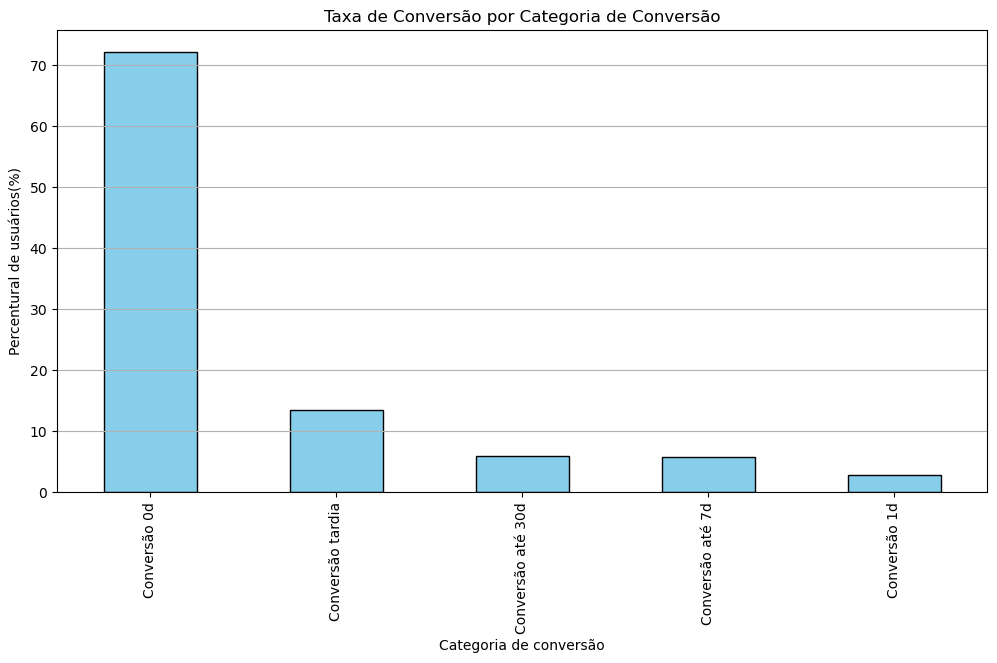

In [22]:
#Quando as pessoas começam a comprar? 
#calcular o primeiro registro do usuário
first_visit = df_visits.groupby('uid')['start_ts'].min().reset_index()
first_visit.columns = ['uid','first_visit']
#calcular a primeira compra por usuário
first_purchase_date = df_orders.groupby('uid')['buy_ts'].min().reset_index()
first_purchase_date.columns = ['uid','first_purchase_date']
#unir as duas tabelas
conversion=first_visit.merge(first_purchase_date,on='uid',how='inner')
#calcular a diferença em dias
conversion['days_to_conversion'] = (
    conversion['first_purchase_date'] - conversion['first_visit']).dt.days
#definir as categorias de conversão
def classify_conversion(days):
    if days == 0:
        return 'Conversão 0d'
    elif days == 1:
        return 'Conversão 1d'
    elif days <= 7:
        return 'Conversão até 7d'
    elif days <= 30:
        return 'Conversão até 30d'
    else:
        return 'Conversão tardia'

conversion['conversion_category'] = conversion['days_to_conversion'].apply(classify_conversion)

#calcular proporções
conversion_stats = conversion['conversion_category'].value_counts(normalize=True)*100
print(conversion_stats)


plt.figure(figsize=(12,6))
conversion_stats.plot(kind='bar',color = 'skyblue',edgecolor = 'black')
plt.title('Taxa de Conversão por Categoria de Conversão')
plt.xlabel('Categoria de conversão')
plt.ylabel('Percentural de usuários(%)')
plt.grid(axis='y')
plt.show()



A maioria esmagadora dos clientes converte no mesmo dia da primeira visita. Isso mostra que o processo de aquisição está muito eficiente: quem chega já decide rápido, outra fatia relevante é a conversão tardia ela pode indicar os clientes que precisam de mais tempo de decisão ou de estímulos adicionais (remarketing, follow-up, promoções).

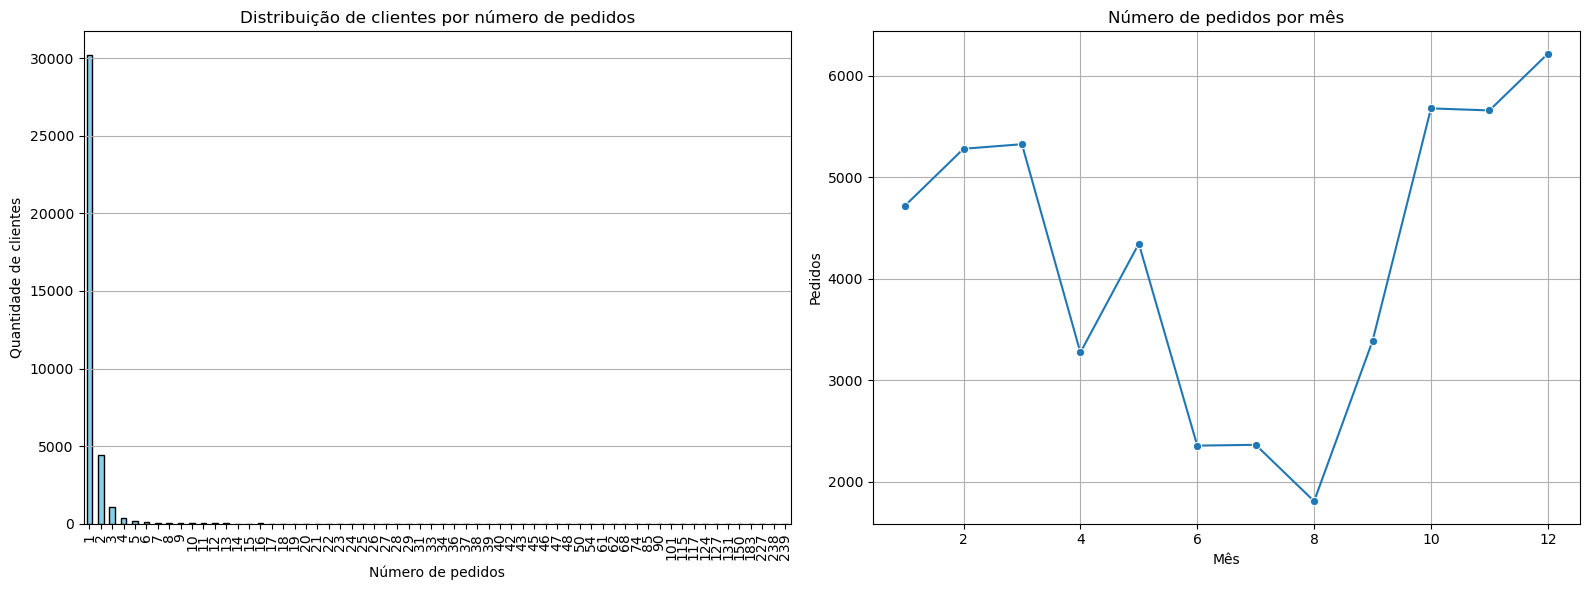

In [23]:
#Quantos pedidos os clientes fazem durante um determinado período de tempo?
#contar pedidos por cliente
orders_per_user = df_orders.groupby('uid').size().reset_index(name='num_orders')
#contar quantos clientes estão em cada número de pedido
distribuição = orders_per_user['num_orders'].value_counts().sort_index()
#contar pedidos por período ( escolhi mensal para ver sazonalidade)
orders_by_month=(df_orders.groupby('dt_month').size().reset_index(name='num_orders'))
# --- Plot lado a lado ---
fig, axes = plt.subplots(1, 2, figsize=(16,6))

# Gráfico 1: clientes por número de pedidos
distribuição.plot(kind='bar', color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Distribuição de clientes por número de pedidos')
axes[0].set_xlabel('Número de pedidos')
axes[0].set_ylabel('Quantidade de clientes')
axes[0].grid(axis='y')

# Gráfico 2: pedidos por mês
sns.lineplot(data=orders_by_month, x='dt_month', y='num_orders', marker='o', ax=axes[1])
axes[1].set_title('Número de pedidos por mês')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Pedidos')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Quantos pedidos os clientes fazem durante um determinado período de tempo?
Distribuição por cliente:
  A maioria dos clientes fez apenas 1 pedido (30.231).  
  Um grupo menor fez 2 pedidos (4.395), e poucos fizeram mais de 5 pedidos.  
  Isso indica que a base de clientes é composta principalmente por compradores ocasionais.

Distribuição por mês:
  Em janeiro foram feitos 4.721 pedidos, em fevereiro 5.281, em março 5.326, etc.  
  Observamos que o volume de pedidos varia ao longo do tempo, sugerindo sazonalidade.

Conclusão: 
A empresa tem muitos clientes que compram apenas uma vez, mas também existe um grupo fiel que faz várias compras. Além disso, o número de pedidos varia mês a mês, o que pode estar ligado a campanhas de marketing ou sazonalidade(dezembro).

In [24]:
#Qual é o volume médio de uma compra? (ticket médio=Receita total/nº de pedidos)
receita_total = df_orders['revenue'].sum()
quantidade_pedidos = df_orders['uid'].shape[0]
ticket_médio=receita_total/quantidade_pedidos
print(ticket_médio)


4.999646930477041


In [25]:
#Quanto dinheiro eles trazem para a empresa (LTV)? LTV = Receita total ÷ número de clientes únicos = LTV médio.
receita_total = df_orders['revenue'].sum()
quantidade_pedidos = df_orders['uid'].nunique()
LTV=receita_total/quantidade_pedidos
print(LTV)


6.9013279303452615


### Marketing

In [26]:
#Quanto dinheiro foi gasto? No total/por origem/ao longo do tempo

#total
total_costs=df_costs['costs'].sum()
print("O custo total foi de:", total_costs)
#por origem
source_costs = df_costs.groupby('source_id')['costs'].sum().sort_values(ascending=False)
print("O custo por origem foi de:", source_costs)
#ao longo do tempo
time_per_costs = df_costs.groupby('dt_month')['costs'].sum()
print("O custo do londo do tempos (meses) foi de:", time_per_costs)

O custo total foi de: 329131.62
O custo por origem foi de: source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64
O custo do londo do tempos (meses) foi de: dt_month
1     33518.52
2     32723.03
3     30415.27
4     22289.38
5     22224.27
6     18015.00
7     18240.59
8     14790.54
9     24368.91
10    36322.88
11    37907.88
12    38315.35
Name: costs, dtype: float64


In [27]:
#Quanto custou a aquisição de clientes para cada origem? CAC = custo total ÷ número de novos clientes adquiridos.

# Pegar a primeira visita de cada cliente
first_visit = (
    df_visits.sort_values(by=['uid','start_ts'])
    .groupby('uid', as_index=False)
    .first()[['uid','source_id','device','start_ts']]
)
# Criar coluna de mês (como período mensal)
first_visit['month'] = first_visit['start_ts'].dt.to_period('M')

clients_per_source_device = (
    first_visit.groupby(['source_id','device'])
    .agg(clients=('uid','nunique'))
    .reset_index()
)
    
source_costs = (
    df_costs.groupby('source_id')['costs']
    .sum()
    .reset_index()
)

cac_df = clients_per_source_device.merge(source_costs, on='source_id', how='left')
cac_df['CAC'] = cac_df['costs'] / cac_df['clients']

print(cac_df.sort_values(by='CAC', ascending=False))


    source_id   device  clients      costs       CAC
5           3    touch    15926  141321.63  8.873642
3           2    touch     5845   42806.04  7.323531
1           1    touch     3122   20833.27  6.673053
9           5    touch    13415   51757.10  3.858151
2           2  desktop    11771   42806.04  3.636568
15          9    touch     1620    5517.49  3.405858
0           1  desktop     6347   20833.27  3.282381
17         10    touch     2057    5822.49  2.830574
4           3  desktop    50190  141321.63  2.815733
7           4    touch    25381   61073.60  2.406272
8           5  desktop    35822   51757.10  1.444841
6           4  desktop    46965   61073.60  1.300407
16         10  desktop     4846    5822.49  1.201504
14          9  desktop     4828    5517.49  1.142811
10          6  desktop        2        NaN       NaN
11          6    touch        0        NaN       NaN
12          7  desktop       24        NaN       NaN
13          7    touch        8        NaN    

C:\Users\dezac\AppData\Local\Temp\ipykernel_368\3909028730.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  first_visit.groupby(['source_id','device'])


Dispositivo importa: em várias origens, o CAC no desktop é bem menor que no touch.
Origem 5 → muito cara no touch (8.87), mas barata no desktop (1.44).
Origem 4 → mesma lógica: cara no touch (2.40), barata no desktop (1.30).
Isso mostra que a eficiência varia bastante entre dispositivos.

In [28]:
#LTV por origem 
# Receita por cliente
revenue_per_client = df_orders.groupby('uid')['revenue'].sum()

# Juntar com origem 
revenue_with_source = first_visit.merge(revenue_per_client, on='uid', how='inner')

# LTV médio por origem
ltv_time = (
    df_orders.merge(first_visit[['uid','source_id','device']], on='uid', how='left')
    .groupby(['source_id','device'])['revenue']
    .mean()
    .reset_index(name='LTV')
)

print(ltv_time.head())

   source_id   device       LTV
0          1  desktop  6.007765
1          1    touch  5.686328
2          2  desktop  7.729499
3          2    touch  5.601525
4          3  desktop  4.186912


C:\Users\dezac\AppData\Local\Temp\ipykernel_368\805522144.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['source_id','device'])['revenue']


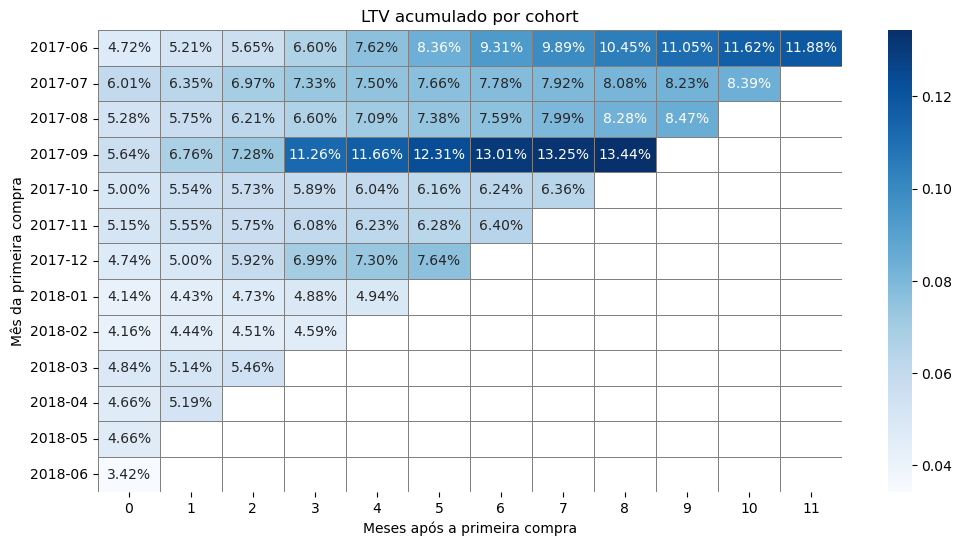

In [29]:

#LTV por coorte
#criando a coluna 'orer_month' a partir da coluna 'buy_ts' que contem a data de compra
df_orders['order_month'] = df_orders['buy_ts'].dt.to_period('M')
#primeira compra
first_order_month = df_orders.groupby('uid')['order_month'].min().reset_index().rename(columns={'order_month' : 'first_order_month'})
#mesclando o DaaFrame original com o DataFrame que contém a data da primeira compra de cada usuário
cohort = pd.merge(df_orders,first_order_month,on='uid')
#calculando a diferença em meses entre a compra atual e a primeira compra
cohort['month_diff'] = (cohort['order_month'].astype('int64') - cohort['first_order_month'].astype('int64'))
#calculando o número de compradores por coorte
cohort_sizes = cohort.groupby('first_order_month')['uid'].nunique().reset_index()
cohort_sizes.rename(columns={'uid': 'n_buyers'},inplace=True)
#mesclando o DataFrame de cohort sizess com o Dataframe principal para obter as informações de compradores
cohort = pd.merge(cohort,cohort_sizes,left_on='first_order_month',right_on = 'first_order_month')
#Calculando o LTV para cada coorte e período de tempo ( em meses) após a primeira compra
cohort['ltv'] = cohort['revenue'] / cohort['n_buyers']/100
#criando a tabela dinaminca
output = cohort.pivot_table(index = 'first_order_month',columns = 'month_diff',values = 'ltv',aggfunc = 'sum')
#calculando LTV acumulado ao longo do tempo para cada coorte
ltv_cumsum = output.cumsum(axis = 1)
#substituindo strings vazias com o NAN
ltv_cumsum.replace('', np.nan, inplace=True)
#gerar Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(ltv_cumsum, cmap="Blues", annot=True, fmt=".2%", linewidths=0.5, linecolor='gray')
plt.title('LTV acumulado por cohort')
plt.xlabel('Meses após a primeira compra')
plt.ylabel('Mês da primeira compra')
plt.show()



In [30]:
#Os investimentos valeram a pena? (ROI) 
# Juntar CAC e LTV
metrics_df = cac_df.merge(ltv_time, on=['source_id','device'], how='inner')

# Calcular ROI em percentual
metrics_df['ROI_%'] = ((metrics_df['LTV'] - metrics_df['CAC']) / metrics_df['CAC']) * 100

print(metrics_df.sort_values(by='ROI_%', ascending=False))


    source_id   device  clients      costs       CAC       LTV       ROI_%
8           5  desktop    35822   51757.10  1.444841  5.953635  312.061565
6           4  desktop    46965   61073.60  1.300407  4.396452  238.082824
12          9  desktop     4828    5517.49  1.142811  3.557317  211.277912
14         10  desktop     4846    5822.49  1.201504  2.937282  144.467010
2           2  desktop    11771   42806.04  3.636568  7.729499  112.549275
0           1  desktop     6347   20833.27  3.282381  6.007765   83.030728
7           4    touch    25381   61073.60  2.406272  4.397970   82.771085
4           3  desktop    50190  141321.63  2.815733  4.186912   48.697058
9           5    touch    13415   51757.10  3.858151  3.762933   -2.467974
13          9    touch     1620    5517.49  3.405858  3.200681   -6.024239
15         10    touch     2057    5822.49  2.830574  2.541580  -10.209704
1           1    touch     3122   20833.27  6.673053  5.686328  -14.786702
3           2    touch   

Origem 5 desktop → CAC ≈ 1.44, LTV ≈ 8.20, ROI ≈ 468%.
Origem 9 desktop → CAC ≈ 1.14, LTV ≈ 5.45, ROI ≈ 377%.
Origem 4 desktop → CAC ≈ 1.30, LTV ≈ 5.47, ROI ≈ 321%. 
Esses canais são super rentáveis: cada cliente gera várias vezes o custo de aquisição. 
São os melhores investimentos.
Origem 2 desktop → ROI ≈ 319%.
Origem 1 desktop → ROI ≈ 250%.
Origem 10 desktop → ROI ≈ 184%.
Ainda muito positivos, mas não tão extraordinários quanto os três primeiros.

Origem 9 touch → ROI ≈ 34%.
Origem 5 touch → ROI ≈ 23%.
Origem 1 touch → ROI ≈ 20%.
Origem 10 touch → ROI ≈ 9%.
Origem 2 touch → ROI ≈ 4%. 
Esses canais ainda dão retorno positivo, mas quase no limite. O custo de aquisição é alto em relação ao LTV.

Investimentos valeram a pena na maioria das origens, especialmente no desktop (ROI muito alto).
Touch/mobile é mais caro e menos eficiente em quase todas as origens.
Origem 3 touch é deficitária: precisa ser revista ou cortada.
Desktop é o grande destaque: origens 5, 9 e 4 são os campeões de ROI.

Construa gráficos para ver como essas métricas diferem para vários dispositivos e diferentes origens de anúncios e como elas mudam com o tempo

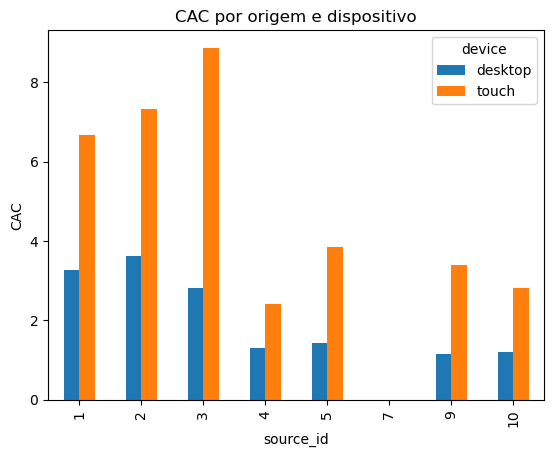

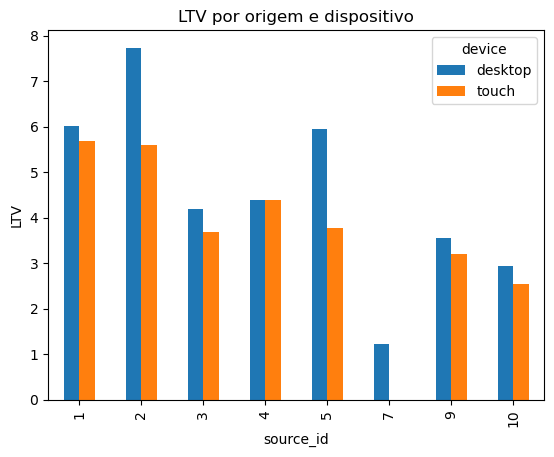

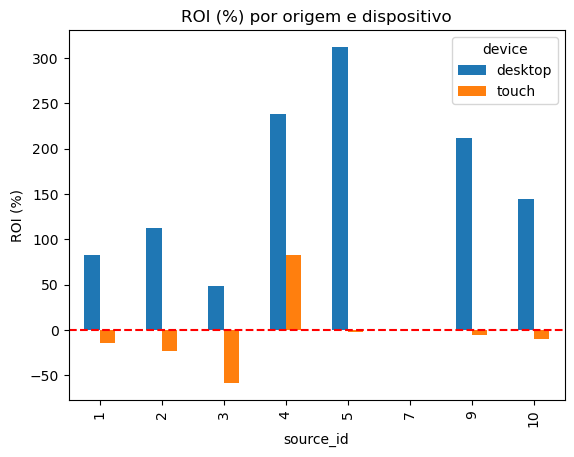

In [31]:
# CAC por origem e dispositivo
metrics_df.pivot(index='source_id', columns='device', values='CAC').plot(kind='bar')
plt.title('CAC por origem e dispositivo')
plt.ylabel('CAC')
plt.show()

# LTV por origem e dispositivo
metrics_df.pivot(index='source_id', columns='device', values='LTV').plot(kind='bar')
plt.title('LTV por origem e dispositivo')
plt.ylabel('LTV')
plt.show()

# ROI por origem e dispositivo
metrics_df.pivot(index='source_id', columns='device', values='ROI_%').plot(kind='bar')
plt.title('ROI (%) por origem e dispositivo')
plt.ylabel('ROI (%)')
plt.axhline(0, color='red', linestyle='--')
plt.show()

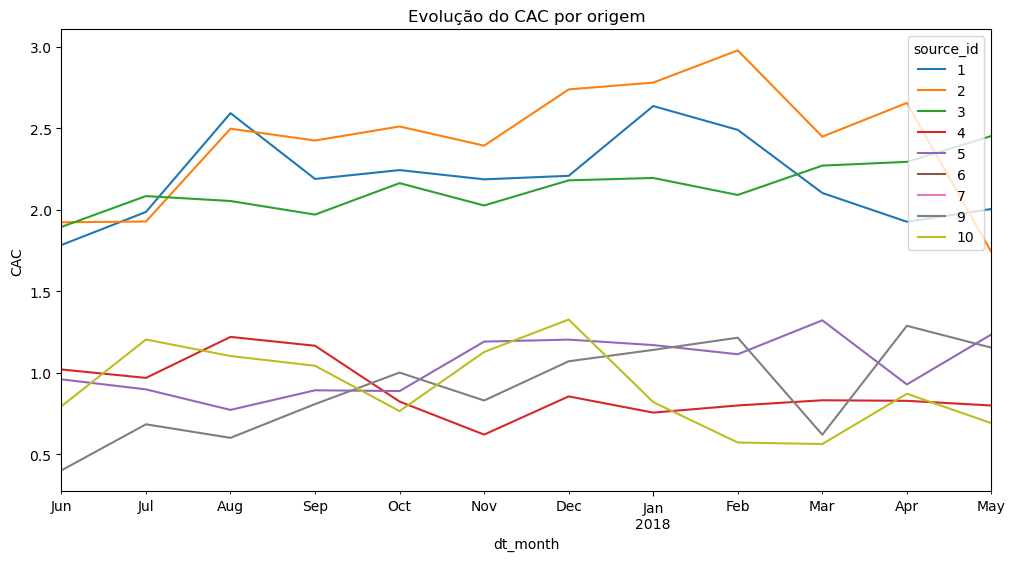

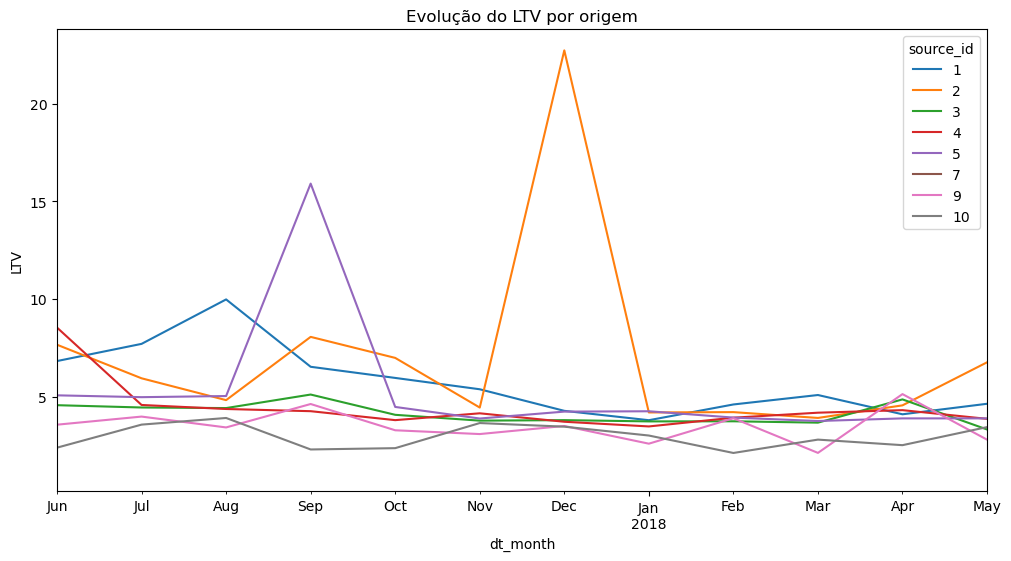

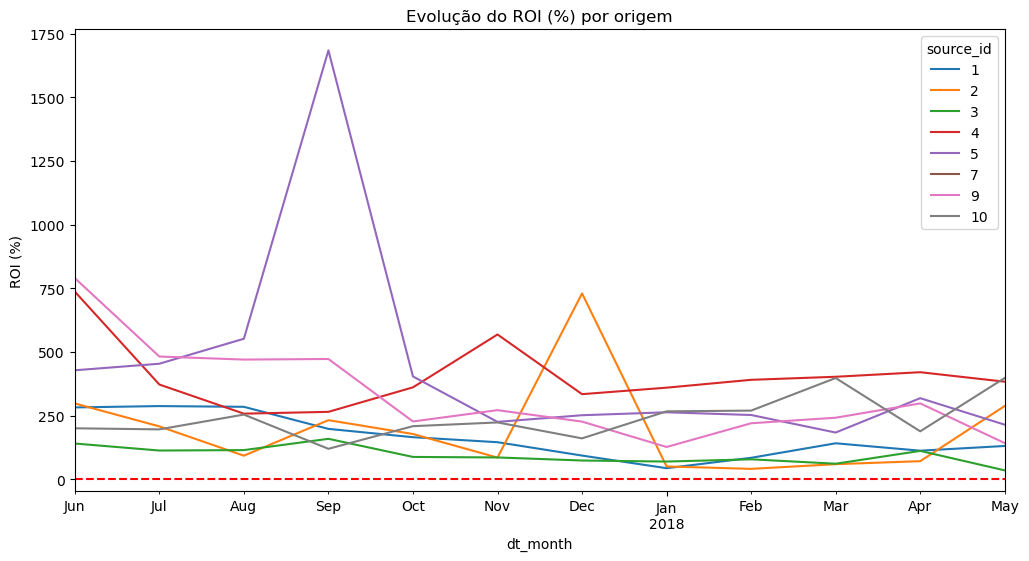

In [33]:
# --- Preparar dados de visitas e custos ---
# garantir que colunas de datas estão em formato datetime
df_visits['start_ts'] = pd.to_datetime(df_visits['start_ts'])
df_costs['dt'] = pd.to_datetime(df_costs['dt'])

# pegar a primeira visita de cada cliente (coorte de aquisição)
first_visit = (
    df_visits.sort_values(by=['uid','start_ts'])
    .groupby('uid', as_index=False)
    .first()[['uid','source_id','start_ts']]
)

# criar coluna de mês da primeira visita (coorte)
first_visit['dt_month'] = first_visit['start_ts'].dt.to_period('M')

# criar coluna de mês nos custos
df_costs['dt_month'] = df_costs['dt'].dt.to_period('M')

# --- Clientes por mês e origem ---
clients_per_month = (
    first_visit.groupby(['dt_month','source_id'])
    .size()
    .reset_index(name='clients')
)

# --- Custos por mês e origem ---
source_costs = (
    df_costs.groupby(['dt_month','source_id'])['costs']
    .sum()
    .reset_index()
)

# --- CAC ao longo do tempo ---
cac_time = clients_per_month.merge(source_costs, on=['dt_month','source_id'], how='left')
cac_time['CAC'] = cac_time['costs'] / cac_time['clients']

cac_time.pivot(index='dt_month', columns='source_id', values='CAC').plot(figsize=(12,6))
plt.title('Evolução do CAC por origem')
plt.ylabel('CAC')
plt.show()

# --- LTV ao longo do tempo ---
# garantir datetime nos pedidos
df_orders['buy_ts'] = pd.to_datetime(df_orders['buy_ts'])

# juntar pedidos com coorte (primeira visita)
orders_with_cohort = df_orders.merge(
    first_visit[['uid','source_id','dt_month']],
    on='uid',
    how='left'
)

# calcular LTV por coorte (mês da primeira visita + origem)
ltv_time = ( orders_with_cohort.
    groupby(['dt_month_y','source_id'])['revenue'] 
    .mean() .reset_index() .rename(columns={'dt_month_y':'dt_month'}) )

# plotar evolução do LTV
ltv_time.pivot(index='dt_month', columns='source_id', values='revenue').plot(figsize=(12,6)) 
plt.title('Evolução do LTV por origem') 
plt.ylabel('LTV') 
plt.show()

# --- ROI ao longo do tempo ---
roi_time = cac_time.merge(ltv_time, on=['dt_month','source_id'], how='inner')
roi_time['ROI_%'] = ((roi_time['revenue'] - roi_time['CAC']) / roi_time['CAC']) * 100

roi_time.pivot(index='dt_month', columns='source_id', values='ROI_%').plot(figsize=(12,6))
plt.title('Evolução do ROI (%) por origem')
plt.ylabel('ROI (%)')
plt.axhline(0, color='red', linestyle='--')
plt.show()

In [ ]:
#Roi/Romi por cohort

# Primeiro, criar as colunas necessárias
df_orders['order_month'] = df_orders['buy_ts'].dt.to_period('M')

# Encontrar o mês da primeira compra de cada usuário
first_order_month = df_orders.groupby('uid')['order_month'].min().reset_index()
first_order_month.columns = ['uid', 'first_order_month']

# Juntar pedidos com primeira visita para obter source_id
orders_with_source = df_orders.merge(
    first_visit[['uid', 'source_id']], 
    on='uid', 
    how='left'
)

# Juntar com primeira compra
df_orders_with_cohort = orders_with_source.merge(first_order_month, on='uid')

# Agrupar por coorte, mês do pedido e origem
cohorts = df_orders_with_cohort.groupby(['first_order_month','order_month','source_id']).agg(
    revenue=('revenue','sum'),
    n_buyers=('uid','nunique')
).reset_index()

# Calcular a vida útil do coorte
cohorts['cohort_lifetime'] = (cohorts['order_month'] - cohorts['first_order_month']).apply(lambda x: x.n)

# Ordenar o dataframe
cohorts = cohorts.sort_values(['first_order_month','cohort_lifetime'])

# Mesclar com os dados de custo
df_costs['costs_month'] = df_costs['dt'].dt.to_period('M')
cost_per_month = df_costs.groupby(['costs_month','source_id']).agg(costs=('costs','sum')).reset_index()

cohorts = pd.merge(cohorts, cost_per_month,
                   left_on=['first_order_month','source_id'],
                   right_on=['costs_month','source_id'],
                   how='left')

# Calcular CAC, LTV e ROMI
cohorts['cac'] = cohorts['costs'] / cohorts['n_buyers']
cohorts['ltv'] = cohorts['revenue'] / cohorts['n_buyers']
cohorts['romi'] = cohorts['ltv'] / cohorts['cac']

# Criar a tabela dinâmica
romi_pivot = cohorts.pivot_table(
    index=['first_order_month','source_id'],
    columns='cohort_lifetime',
    values='romi',
    aggfunc='mean'
).round(2)

# Calcular soma acumulada
romi_cumsum = romi_pivot.cumsum(axis=1).round(2)

print("ROMI por coorte e origem:")
print(romi_pivot)

print("\nROMI acumulado por coorte e origem:")
print(romi_cumsum)

ROMI por coorte e origem:
cohort_lifetime                0     1     2     3     4     5     6     7   \
first_order_month source_id                                                   
2017-06           1          1.22  0.37  0.37  0.63  0.72  0.35  0.44  0.43   
                  2          0.43  0.05  0.03  0.19  0.16  0.09  0.16  0.14   
                  3          0.36  0.01  0.02  0.03  0.02  0.02  0.01  0.00   
                  4          0.56  0.00  0.02  0.05  0.13  0.17  0.17  0.03   
                  5          0.73  0.13  0.07  0.13  0.10  0.04  0.13  0.09   
...                           ...   ...   ...   ...   ...   ...   ...   ...   
2018-05           3          0.35   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
                  4          0.90   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
                  5          0.57   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
                  9          0.62   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
                  10      

### Conclusão

A análise do ROMI (Return on Marketing Investment) por coorte e origem de tráfego revelou insights valiosos sobre a eficiência dos investimentos em marketing da Y.Afisha. Os principais achados incluem:

- **Desempenho Variado por Origem**: Algumas origens, como a 1 no coorte de junho/2017, alcançam ROMI acima de 1 desde o início, indicando payback imediato. Outras, como a 2, demoram meses para se tornarem positivas, sugerindo um retorno mais gradual. Já origens como a 3 nunca atingem ROMI ≥ 1, evidenciando ineficiência persistente.

- **Tempo de Retorno**: O ROMI acumulado destaca diferenças no tempo necessário para rentabilidade. Por exemplo, origens 2 e 4 tipicamente levam cerca de 6 meses para se pagarem, enquanto a origem 3 demonstra que investimentos nessa fonte nunca se recuperam.

- **Implicações Estratégicas**: Esses resultados permitem otimizar alocações de orçamento. Canais com ROMI alto e rápido (ex.: origens 1, 5 e 9) devem receber mais recursos para maximizar crescimento. Origens com retorno lento (ex.: 2 e 4) podem ser mantidas com ajustes, mas origens deficitárias (ex.: 3) devem ser reduzidas ou eliminadas. Além disso, o planejamento financeiro deve incorporar o tempo de payback para evitar subinvestimento em canais promissores.

Essa abordagem baseada em dados não apenas reduz custos desnecessários, mas também acelera o crescimento sustentável, garantindo que cada rublo investido gere o máximo valor possível para a empresa.